# DDM halo emulator — quickstart

Load the closed-form emulator, predict a relaxed density profile, and plot it.
Needs only `numpy` and `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from ddm_emulator import DDMDensity

emu = DDMDensity("../models/semianalytic.npz")
print("tau domain :", emu.tau_domain)
print("v   domain :", emu.v_domain)
print("r   domain :", emu.r_domain, "kpc")

tau domain : (0.5, 10.0)
v   domain : (0.1, 0.5)
r   domain : (2.3071, 171.8904) kpc


## Predict a single profile

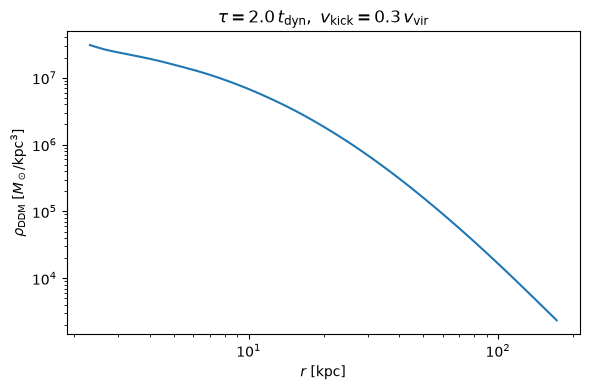

In [2]:
r = np.geomspace(*emu.r_domain, 100)   # kpc
rho = emu(r, tau=2.0, v_kick=0.3)      # tau in t_dyn, v_kick in units of v_vir

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(r, rho)
ax.set_xlabel(r"$r$ [kpc]")
ax.set_ylabel(r"$\rho_{\rm DDM}$ [$M_\odot/{\rm kpc}^3$]")
ax.set_title(r"$\tau=2.0\,t_{\rm dyn},\ v_{\rm kick}=0.3\,v_{\rm vir}$")
plt.tight_layout()

## The decay modification ratio to the control halo

Sweeping `v_kick` shows how the kick reshapes the profile relative to the
non-decaying control `rho_null`.

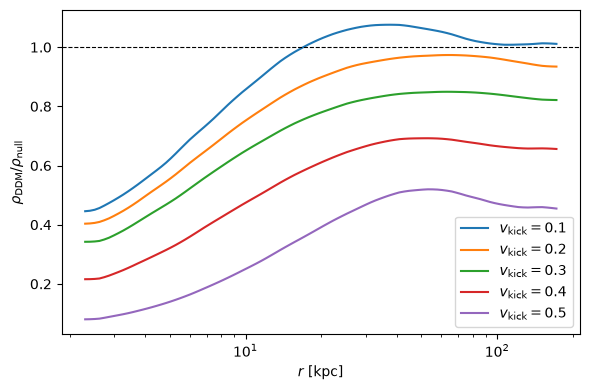

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for v in [0.1, 0.2, 0.3, 0.4, 0.5]:
    ratio = emu(r, tau=2.0, v_kick=v) / emu.null_density(r)
    ax.semilogx(r, ratio, label=f"$v_{{\\rm kick}}={v}$")
ax.axhline(1.0, ls="--", color="k", lw=0.8)
ax.set_xlabel(r"$r$ [kpc]")
ax.set_ylabel(r"$\rho_{\rm DDM}/\rho_{\rm null}$")
ax.legend()
plt.tight_layout()

## Inspect the pieces

The four PCA amplitudes `c_k(tau, v_kick)` and the fixed radial functions are
all accessible if you want to build your own reconstruction.

In [4]:
print("c_k(tau=2, v_kick=0.3) =", emu.coefficients(2.0, 0.3))
print("radial grid points    :", emu.r_grid.size)
print("number of PCA modes   :", emu.e_modes.shape[0])

c_k(tau=2, v_kick=0.3) = [ 1.29534329 -0.25478079  0.08066165  0.01948881]
radial grid points    : 64
number of PCA modes   : 4
